# Synthetic atrial-flow verification with prescribed kinematics

What can a conservative, converging synthetic chamber calculation establish—and what would real atrial CFD validation still require?

Fall 2024.


## Predict and identify the model
This original atrial-inspired chamber uses prescribed kinematics, not a momentum solver. Predict whether changing the interior streamfunction parameter can change motion while preserving port flow. Record which evidence would be needed for physiological validation.

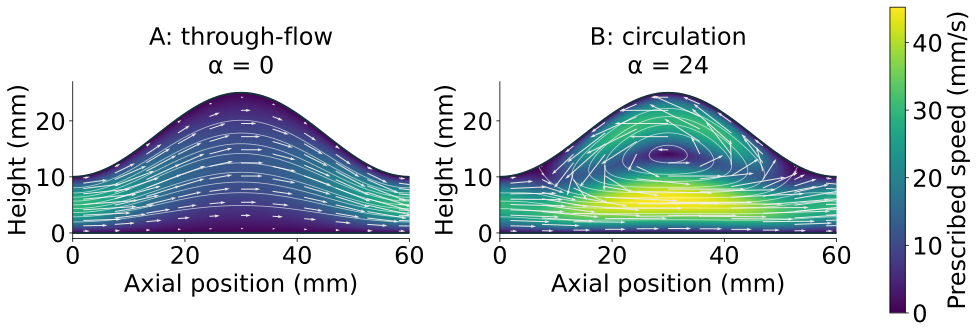

[0.030000000000000002, 0.0452197265625]

In [1]:
import numpy as np
from demo import field, velocity_diagnostics, run
from IPython.display import SVG, display
report=run()
display(SVG(filename="synthetic-chamber.svg"))
report["two_fields_max_speeds_m_s"]

## Implement a guided boundary account
The reusable diagnostic accepts X,Y,u,v arrays on y=ηH(x), uniform η, with shape (x nodes, η nodes), and SI units. It can receive a compatible imported velocity field. Implement net outward flow from its component fluxes; the starter runs and may be replaced with your equivalent expression. No pressure or momentum residual is inferred.

In [2]:
r=field(n=64)
audit=velocity_diagnostics(r["X"],r["Y"],r["u"],r["v"])
def boundary_account(inflow,outflow,wall_outflow):
    return outflow + wall_outflow - inflow
net=boundary_account(audit["inlet_flow_mL_s"],audit["outlet_flow_mL_s"],audit["wall_outward_flow_mL_s"])
assert abs(net-audit["net_outward_boundary_flow_mL_s"])<1e-12
audit

{'divergence_rms_per_s': 0.0022609599748518875,
 'net_outward_boundary_flow_mL_s': 0.0,
 'inlet_flow_mL_s': 3.9990234374999996,
 'outlet_flow_mL_s': 3.9990234374999996,
 'wall_outward_flow_mL_s': 0.0,
 'momentum_residual': 'not assessed; pressure, viscous stress, time derivative and forcing are not supplied'}

## Run a deliberate diagnostic failure
Add a small upward velocity proportional to η. Predict the sign of net boundary flow. This is an intentionally corrupted test field, not an accepted incompressible model.

In [3]:
eta=r["Y"]/r["Y"][:,-1,None]
bad=velocity_diagnostics(r["X"],r["Y"],r["u"],r["v"]+.001*eta)
print("Injected net outward flow (mL/s):",bad["net_outward_boundary_flow_mL_s"])
assert abs(bad["net_outward_boundary_flow_mL_s"]-1.2)<1e-12

Injected net outward flow (mL/s): 1.2


## Modify one boundary input
Change only q, retain the geometry, and predict the bulk volume/flow scale. Distinguish this input sensitivity from derivative refinement and from particle residence time.

0.8 3.2 6.5625
1 4.000000000000001 5.25
1.2 4.800000000000001 4.375


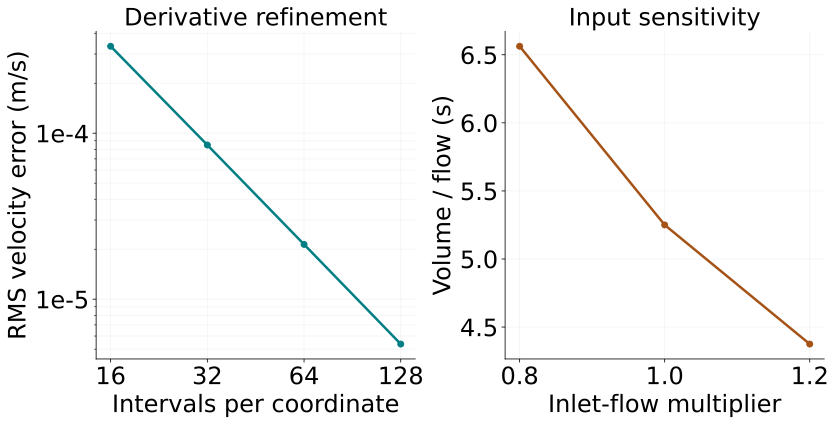

In [4]:
for multiplier in [.8,1,1.2]:
    case=field(q=2e-4*multiplier)
    print(multiplier,case["exact_port_flux_mL_s"],case["volume_over_flow_s"])
display(SVG(filename="chamber-verification.svg"))

## Interpret and prepare the proposed report
State the exact operation whose refinement was measured. Explain why a zero global boundary sum can coexist with a nonzero local divergence diagnostic. List the governing-equation, geometry/boundary and measurement evidence missing from a real atrial validation claim.